In [ ]:
import os
import json
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import tensorflow as tf
from tensorflow.keras import layers, Model
from tensorflow.keras.preprocessing.image import ImageDataGenerator, load_img, img_to_array

BASE_DIR = os.path.abspath(".")
DATA_DIR = os.path.join(BASE_DIR, "data", "horses_humans")
CUSTOM_DIR = os.path.join(BASE_DIR, "data", "custom_test", "horses_humans")
MODELS_DIR = os.path.join(BASE_DIR, "models")
RESULTS_DIR = os.path.join(BASE_DIR, "results")

print(f"TensorFlow Version: {tf.__version__}")
print(f"GPU Available: {tf.config.list_physical_devices('GPU')}")

TensorFlow Version: 2.21.0
GPU Available: []


In [ ]:
with open(os.path.join(RESULTS_DIR, "exp_2_1_summary.json")) as f:
    res_2_1 = json.load(f)
with open(os.path.join(RESULTS_DIR, "exp_2_2_summary.json")) as f:
    res_2_2 = json.load(f)
with open(os.path.join(RESULTS_DIR, "exp_2_3_summary.json")) as f:
    res_2_3 = json.load(f)

print(f"| Експеримент | Вхід | Параметри всього | Навчальні параметри | Валідаційна точність | Кастомний тест (10 фото) |")
print(f"|---|---|---|---|---|---|")
print(f"| 2.1 (300x300 No Aug) | 300x300 | {res_2_1['total_params']:,} | {res_2_1['trainable_params']:,} | {res_2_1['final_val_acc']*100:.2f}% | {res_2_1['custom_test_acc']*100:.1f}% |")
print(f"| 2.2 (150x150 Aug)    | 150x150 | {res_2_2['total_params']:,} | {res_2_2['trainable_params']:,} | {res_2_2['final_val_acc']*100:.2f}% | {res_2_2['custom_test_acc']*100:.1f}% |")
print(f"| 2.3 (150x150 FT)     | 150x150 | {res_2_3['total_params']:,} | {res_2_3['trainable_params']:,} | {res_2_3['final_val_acc']*100:.2f}% | {res_2_3['custom_test_acc']*100:.1f}% |")

| Експеримент | Вхід | Параметри всього | Навчальні параметри | Валідаційна точність | Кастомний тест (10 фото) |
|---|---|---|---|---|---|
| 2.1 (300x300 No Aug) | 300x300 | 236,256,161 | 227,280,897 | 94.14% | 90.0% |
| 2.2 (150x150 Aug)    | 150x150 | 47,512,481 | 38,537,217 | 99.61% | 70.0% |
| 2.3 (150x150 FT)     | 150x150 | 47,512,481 | 38,537,217 | 99.61% | 80.0% |


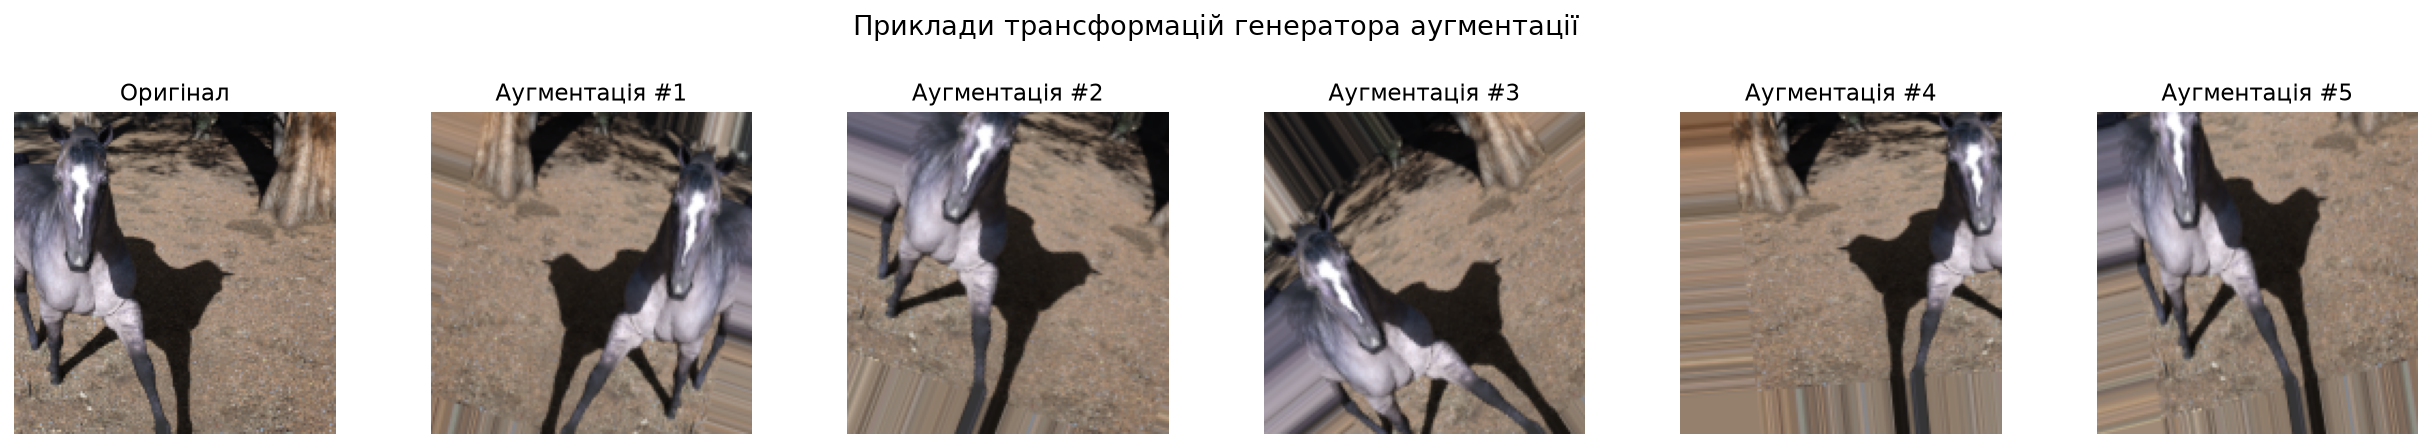

In [ ]:
sample_img_dir = os.path.join(DATA_DIR, "training", "horses")
sample_img_file = [f for f in os.listdir(sample_img_dir) if f.endswith(('.png', '.jpg', '.jpeg'))][0]
sample_img_path = os.path.join(sample_img_dir, sample_img_file)
sample_img = load_img(sample_img_path, target_size=(150, 150))
sample_arr = img_to_array(sample_img)
sample_arr = np.expand_dims(sample_arr, axis=0)

datagen = ImageDataGenerator(
    rotation_range=40,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest'
)

fig, axes = plt.subplots(1, 6, figsize=(18, 3))
axes[0].imshow(sample_img)
axes[0].set_title("Оригінал")
axes[0].axis('off')

gen = datagen.flow(sample_arr, batch_size=1)
for i in range(1, 6):
    batch = next(gen)
    axes[i].imshow(batch[0].astype('uint8'))
    axes[i].set_title(f"Аугментація #{i}")
    axes[i].axis('off')

plt.suptitle("Приклади трансформацій генератора аугментації", fontsize=14, y=1.05)
plt.tight_layout()
plt.show()

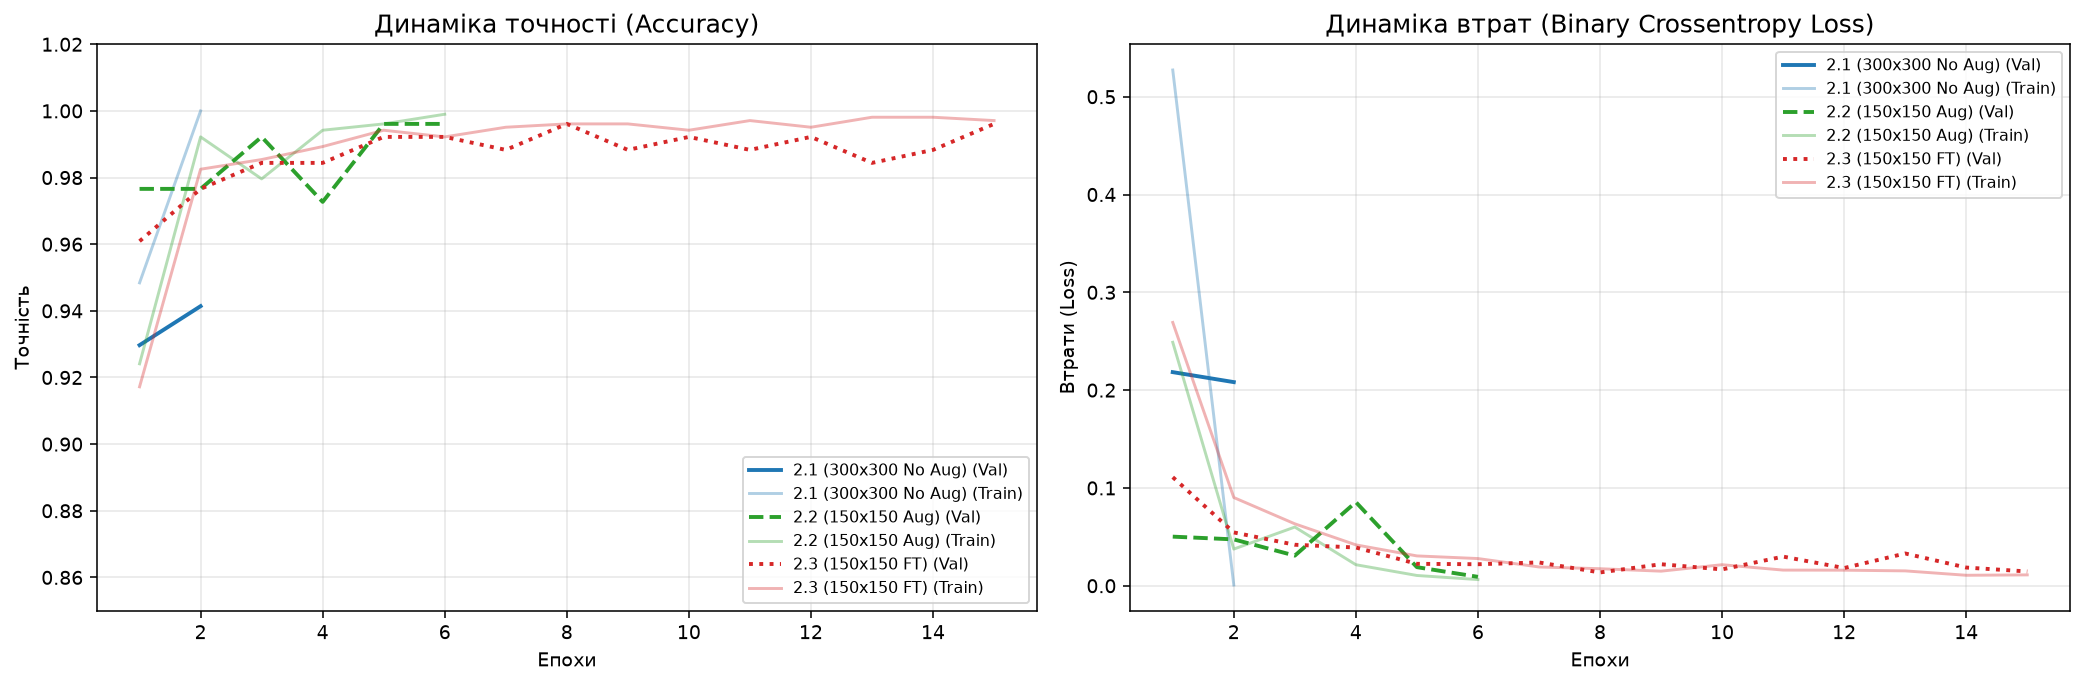

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for exp_name, data, color, ls in [
    ("2.1 (300x300 No Aug)", res_2_1, "tab:blue", "-"),
    ("2.2 (150x150 Aug)", res_2_2, "tab:green", "--"),
    ("2.3 (150x150 FT)", res_2_3, "tab:red", ":")
]:
    hist = data["history"]
    epochs = range(1, len(hist["accuracy"]) + 1)
    axes[0].plot(epochs, hist["val_accuracy"], label=f"{exp_name} (Val)", color=color, linestyle=ls, linewidth=2)
    axes[0].plot(epochs, hist["accuracy"], label=f"{exp_name} (Train)", color=color, alpha=0.35)

axes[0].set_title("Динаміка точності (Accuracy)", fontsize=13)
axes[0].set_xlabel("Епохи")
axes[0].set_ylabel("Точність")
axes[0].set_ylim(0.85, 1.02)
axes[0].grid(True, alpha=0.3)
axes[0].legend(loc="lower right", fontsize=8)

for exp_name, data, color, ls in [
    ("2.1 (300x300 No Aug)", res_2_1, "tab:blue", "-"),
    ("2.2 (150x150 Aug)", res_2_2, "tab:green", "--"),
    ("2.3 (150x150 FT)", res_2_3, "tab:red", ":")
]:
    hist = data["history"]
    epochs = range(1, len(hist["loss"]) + 1)
    axes[1].plot(epochs, hist["val_loss"], label=f"{exp_name} (Val)", color=color, linestyle=ls, linewidth=2)
    axes[1].plot(epochs, hist["loss"], label=f"{exp_name} (Train)", color=color, alpha=0.35)

axes[1].set_title("Динаміка втрат (Binary Crossentropy Loss)", fontsize=13)
axes[1].set_xlabel("Епохи")
axes[1].set_ylabel("Втрати (Loss)")
axes[1].grid(True, alpha=0.3)
axes[1].legend(loc="upper right", fontsize=8)

plt.tight_layout()
plt.show()

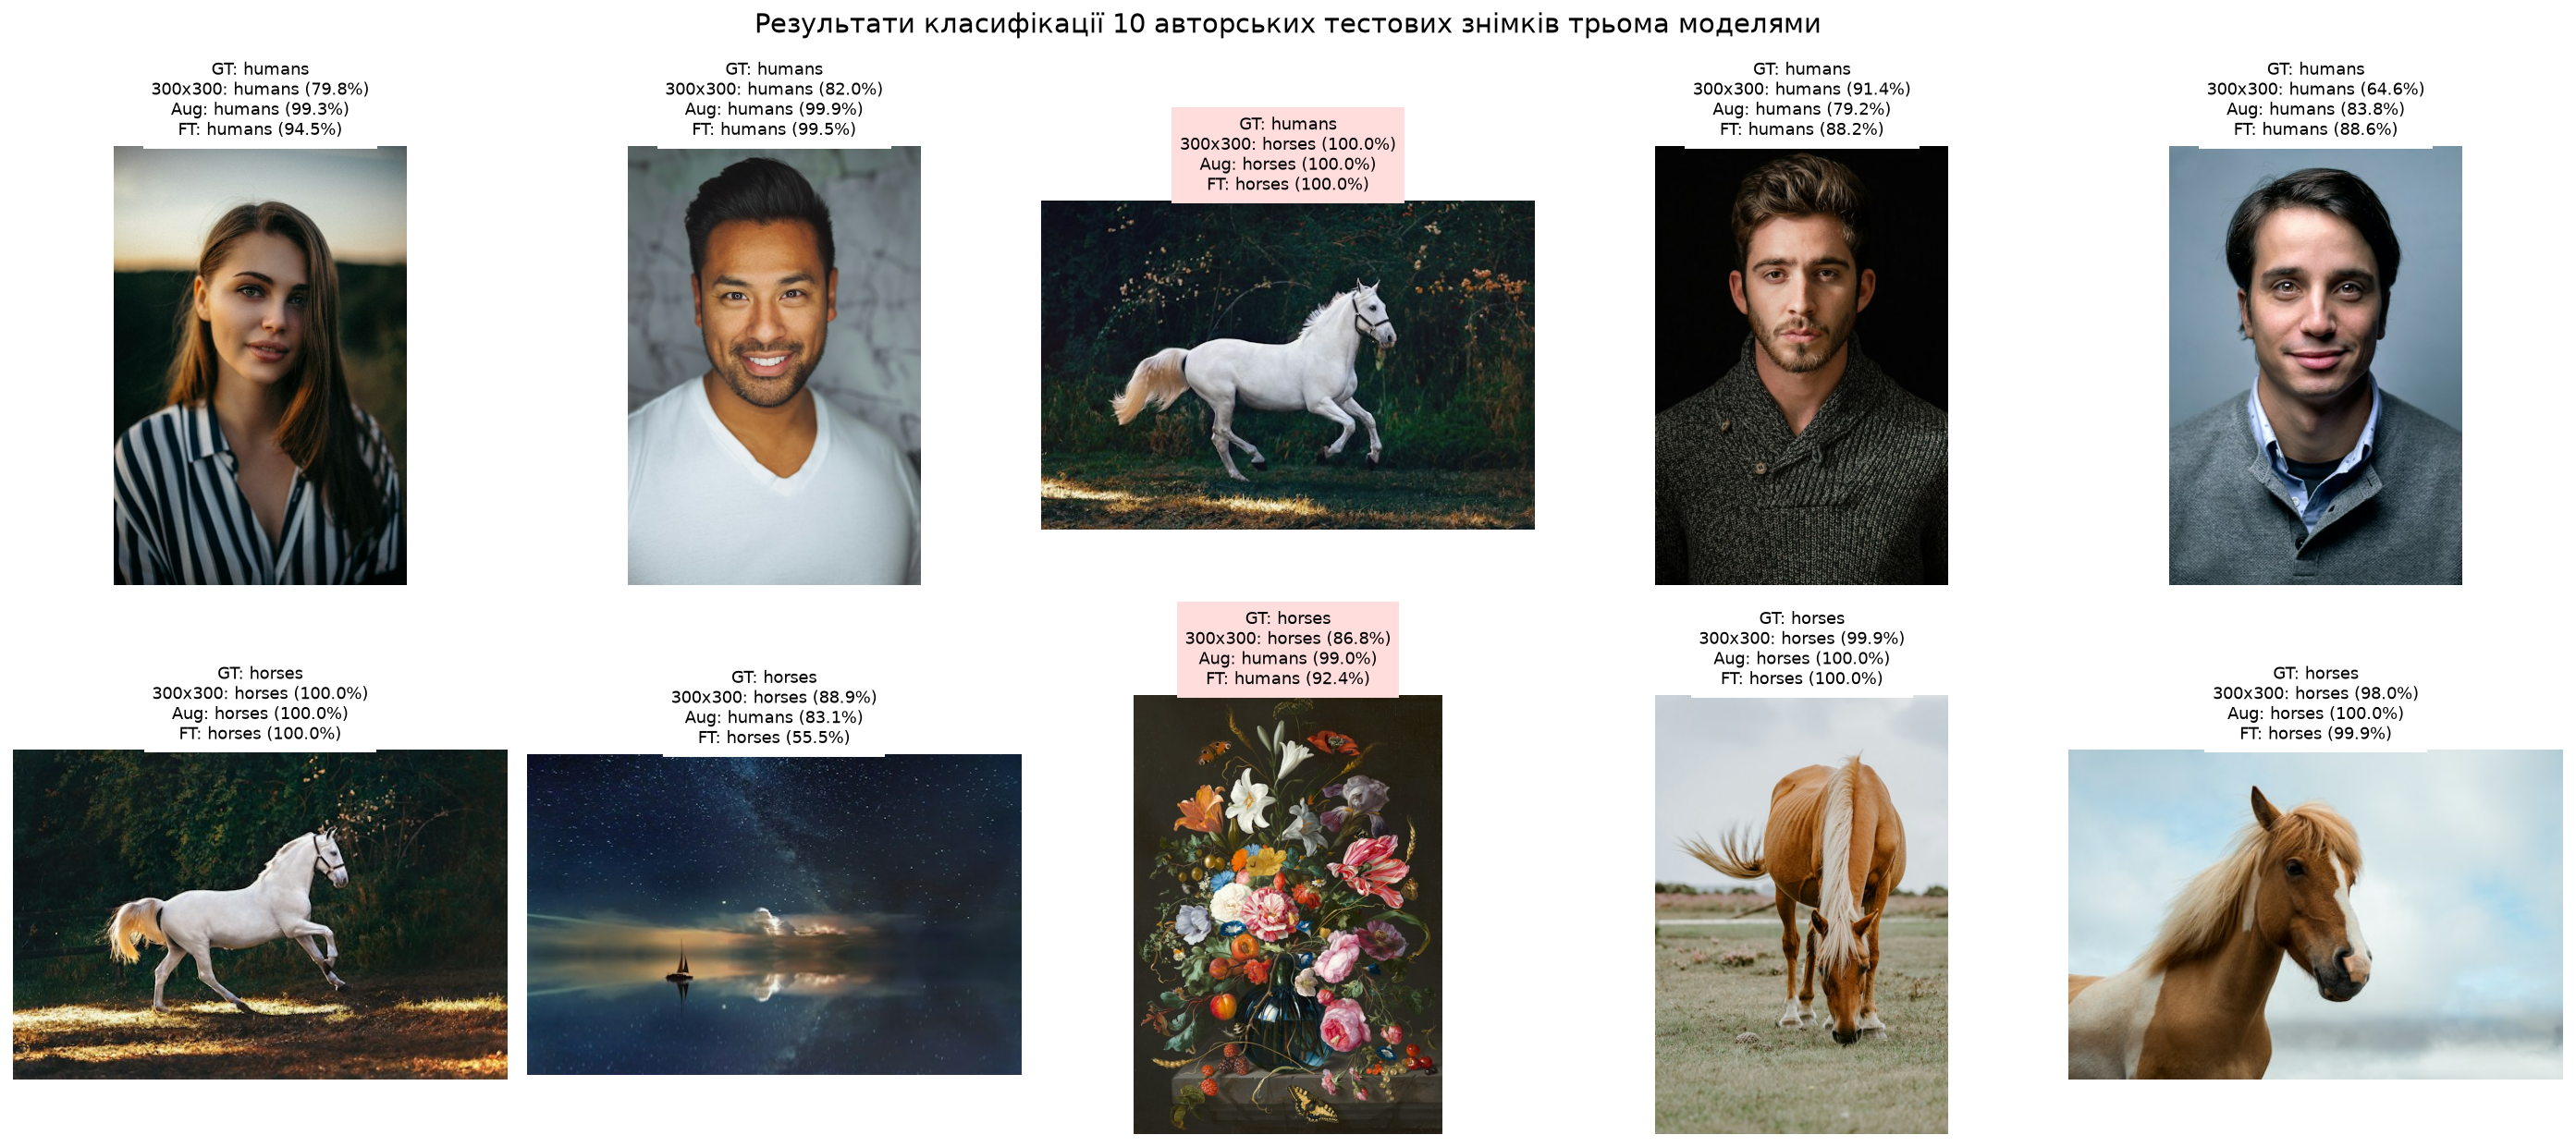

In [ ]:
custom_items = res_2_1["custom_results"]

fig, axes = plt.subplots(2, 5, figsize=(20, 9))
axes = axes.flatten()

for idx, item in enumerate(custom_items):
    fname = item["filename"]
    img_path = os.path.join(CUSTOM_DIR, fname)
    img = Image.open(img_path).convert('RGB')
    
    p1 = item["pred_class"]
    c1 = item["confidence"]
    p2 = res_2_2["custom_results"][idx]["pred_class"]
    c2 = res_2_2["custom_results"][idx]["confidence"]
    p3 = res_2_3["custom_results"][idx]["pred_class"]
    c3 = res_2_3["custom_results"][idx]["confidence"]
    
    gt = item["true_class"]
    
    axes[idx].imshow(img)
    axes[idx].set_title(
        f"GT: {gt}\n"
        f"300x300: {p1} ({c1*100:.1f}%)\n"
        f"Aug: {p2} ({c2*100:.1f}%)\n"
        f"FT: {p3} ({c3*100:.1f}%)",
        fontsize=9,
        backgroundcolor='white' if (p3 == gt) else '#ffdddd'
    )
    axes[idx].axis('off')

plt.suptitle("Результати класифікації 10 авторських тестових знімків трьома моделями", fontsize=15, y=0.98)
plt.tight_layout()
plt.show()

In [ ]:
print(f"{'Файл':<28} | {'Істинний клас':<10} | {'300x300':<12} | {'150x150 Aug':<12} | {'150x150 FT':<12} | Опис")
print("-" * 110)
for idx, it in enumerate(custom_items):
    p1 = f"{res_2_1['custom_results'][idx]['pred_class']} ({res_2_1['custom_results'][idx]['confidence']*100:.0f}%)"
    p2 = f"{res_2_2['custom_results'][idx]['pred_class']} ({res_2_2['custom_results'][idx]['confidence']*100:.0f}%)"
    p3 = f"{res_2_3['custom_results'][idx]['pred_class']} ({res_2_3['custom_results'][idx]['confidence']*100:.0f}%)"
    print(f"{it['filename']:<28} | {it['true_class']:<10} | {p1:<12} | {p2:<12} | {p3:<12} | {it['description']}")

Файл                         | Істинний клас | 300x300      | 150x150 Aug  | 150x150 FT   | Опис
--------------------------------------------------------------------------------------------------------------
human_01_portrait.jpg        | humans     | humans (80%) | humans (99%) | humans (95%) | Standard female portrait
human_02_standing.jpg        | humans     | humans (82%) | humans (100%) | humans (99%) | Man smiling standing
human_03_rider_on_horse.jpg  | humans     | horses (100%) | horses (100%) | horses (100%) | TRICK: Person actively riding on a horse
human_04_silhouette.jpg      | humans     | humans (91%) | humans (79%) | humans (88%) | Male close portrait with shadows
human_05_sitting.jpg         | humans     | humans (65%) | humans (84%) | humans (89%) | Man sitting outdoors
horse_01_pasture.jpg         | horses     | horses (100%) | horses (100%) | horses (100%) | Brown horse grazing in green pasture
horse_02_white_gallop.jpg    | horses     | horses (89%) | humans (83%) |